In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Загружаем обработанный датасет из лабораторной №1
df = pd.read_csv("data/processed_titanic.csv")

# Проверяем размер и первые строки
print("Размер датасета:", df.shape)
display(df.head())

# Выводим информацию о столбцах
df.info()

Размер датасета: (891, 11)


,PassengerId,Survived,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S,Pclass_2,Pclass_3
0,1,0,0.271174,0.125,0.0,0.014151,1,0,1,0,1
1,2,1,0.472229,0.125,0.0,0.139136,0,0,0,0,0
2,3,1,0.321438,0.000,0.0,0.015469,0,0,1,0,1
3,4,1,0.434531,0.125,0.0,0.103644,0,0,1,0,0
4,5,0,0.434531,0.000,0.0,0.015713,1,0,1,0,1


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Age          891 non-null    float64
 3   SibSp        891 non-null    float64
 4   Parch        891 non-null    float64
 5   Fare         891 non-null    float64
 6   Sex_male     891 non-null    int64  
 7   Embarked_Q   891 non-null    int64  
 8   Embarked_S   891 non-null    int64  
 9   Pclass_2     891 non-null    int64  
 10  Pclass_3     891 non-null    int64  
dtypes: float64(4), int64(7)
memory usage: 76.7 KB


## Регрессия: прогноз стоимости билета


In [9]:
# Импортируем функцию разделения данных
from sklearn.model_selection import train_test_split

# Формируем признаки для регрессии
# Fare — целевой признак, который нужно предсказать
# PassengerId — идентификатор, он не несёт полезной закономерности
# Survived — результат выживания, его не используем для прогноза стоимости билета
X_reg = df.drop(columns=["Fare", "PassengerId", "Survived"])

# Целевая переменная
y_reg = df["Fare"]

# Разделяем данные:
# 80% — для обучения модели
# 20% — для проверки модели
X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg,
    y_reg,
    test_size=0.2,
    random_state=42
)

print("Размер обучающих признаков:", X_train_reg.shape)
print("Размер тестовых признаков:", X_test_reg.shape)
print("Размер обучающей цели:", y_train_reg.shape)
print("Размер тестовой цели:", y_test_reg.shape)

Размер обучающих признаков: (712, 8)
Размер тестовых признаков: (179, 8)
Размер обучающей цели: (712,)
Размер тестовой цели: (179,)


### Обучение модели линейной регрессии

In [10]:
# Импортируем модель линейной регрессии
from sklearn.linear_model import LinearRegression

# Создаём модель
linear_model = LinearRegression()

# Обучаем модель на обучающей выборке
linear_model.fit(X_train_reg, y_train_reg)

# Получаем предсказания для тестовой выборки
y_pred_reg = linear_model.predict(X_test_reg)

print("Модель обучена")
print("Количество предсказаний:", len(y_pred_reg))

Модель обучена
Количество предсказаний: 179


### Оценка регрессионной модели

In [11]:
# Импортируем метрики для оценки регрессии
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score
)

# Рассчитываем ошибки модели
mae = mean_absolute_error(y_test_reg, y_pred_reg)
mse = mean_squared_error(y_test_reg, y_pred_reg)
rmse = root_mean_squared_error(y_test_reg, y_pred_reg)
r2 = r2_score(y_test_reg, y_pred_reg)

print(f"MAE:  {mae:.4f}")
print(f"MSE:  {mse:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R²:   {r2:.4f}")

MAE:  0.0368
MSE:  0.0036
RMSE: 0.0604
R²:   0.3822


### Визуальное сравнение реальных и предсказанных значений


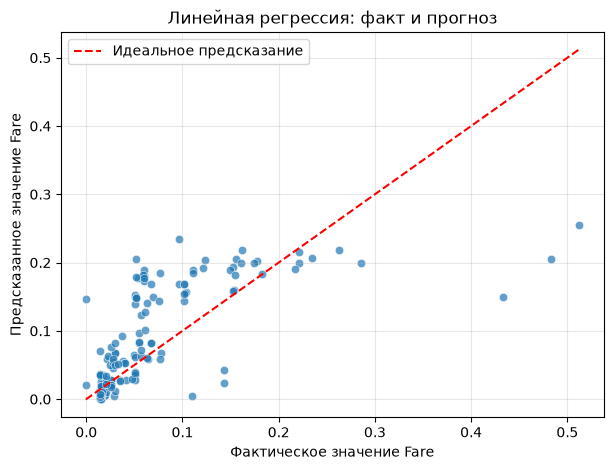

In [12]:
plt.figure(figsize=(7, 5))

sns.scatterplot(
    x=y_test_reg,
    y=y_pred_reg,
    alpha=0.7
)

# Определяем границы графика
min_value = min(y_test_reg.min(), y_pred_reg.min())
max_value = max(y_test_reg.max(), y_pred_reg.max())

# Красная линия показывает идеальное совпадение
plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Идеальное предсказание"
)

plt.xlabel("Фактическое значение Fare")
plt.ylabel("Предсказанное значение Fare")
plt.title("Линейная регрессия: факт и прогноз")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Вывод по регрессии

Линейная регрессия получила значение R² = 0.3822. Это означает, что модель объясняет около 38,22% изменений стоимости билета. Модель лучше предсказывает билеты с небольшой стоимостью, но занижает стоимость дорогих билетов.

Результат можно улучшить следующими способами:

- использовать полиномиальную регрессию для учёта нелинейных зависимостей;
- обработать выбросы в признаке Fare;
- добавить новые информативные признаки;
- применить более сложные модели машинного обучения;
- увеличить объём обучающих данных.

## Классификация: прогноз выживания пассажиров

In [13]:
# Формируем признаки для классификации
# Survived — целевой столбец
# PassengerId — идентификатор, который не используем для обучения
X_cls = df.drop(columns=["Survived", "PassengerId"])

# Целевая переменная:
# 0 — пассажир не выжил
# 1 — пассажир выжил
y_cls = df["Survived"]

# Разделяем данные на обучающую и тестовую выборки
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.2,
    random_state=42,
    stratify=y_cls
)

print("Размер обучающих признаков:", X_train_cls.shape)
print("Размер тестовых признаков:", X_test_cls.shape)
print("Размер обучающей цели:", y_train_cls.shape)
print("Размер тестовой цели:", y_test_cls.shape)

print("\nДоли классов в обучающей выборке:")
print(y_train_cls.value_counts(normalize=True).round(3))

Размер обучающих признаков: (712, 9)
Размер тестовых признаков: (179, 9)
Размер обучающей цели: (712,)
Размер тестовой цели: (179,)

Доли классов в обучающей выборке:
Survived
0    0.617
1    0.383
Name: proportion, dtype: float64


### Обучение модели логистической регрессии

In [14]:
# Импортируем модель логистической регрессии
from sklearn.linear_model import LogisticRegression

# Создаём модель
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Обучаем модель
logistic_model.fit(X_train_cls, y_train_cls)

# Получаем предсказания для тестовой выборки
y_pred_cls = logistic_model.predict(X_test_cls)

print("Модель обучена")
print("Количество предсказаний:", len(y_pred_cls))
print("Первые 10 предсказаний:", y_pred_cls[:10])

Модель обучена
Количество предсказаний: 179
Первые 10 предсказаний: [0 0 0 0 1 0 1 0 0 0]


### Оценка классификационной модели

In [15]:
# Импортируем метрики классификации
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Рассчитываем основные метрики
accuracy = accuracy_score(y_test_cls, y_pred_cls)
precision = precision_score(y_test_cls, y_pred_cls)
recall = recall_score(y_test_cls, y_pred_cls)
f1 = f1_score(y_test_cls, y_pred_cls)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nПодробный отчёт:")
print(
    classification_report(
        y_test_cls,
        y_pred_cls,
        target_names=["Не выжил", "Выжил"]
    )
)

Accuracy:  0.7933
Precision: 0.7759
Recall:    0.6522
F1-score:  0.7087

Подробный отчёт:
              precision    recall  f1-score   support

    Не выжил       0.80      0.88      0.84       110
       Выжил       0.78      0.65      0.71        69

    accuracy                           0.79       179
   macro avg       0.79      0.77      0.77       179
weighted avg       0.79      0.79      0.79       179



### Матрица ошибок

Матрица ошибок:
[[97 13]
 [24 45]]


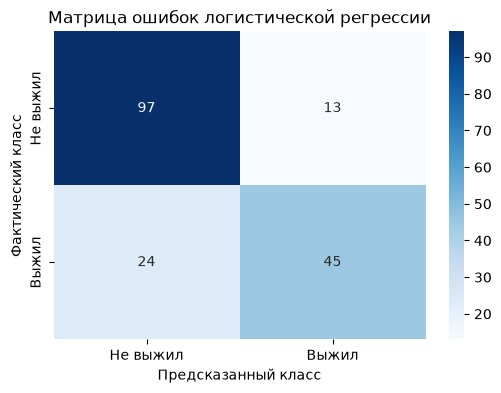

In [16]:
# Импортируем функцию построения матрицы ошибок
from sklearn.metrics import confusion_matrix

# Рассчитываем матрицу ошибок
cm = confusion_matrix(y_test_cls, y_pred_cls)

print("Матрица ошибок:")
print(cm)

# Визуализируем матрицу
plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Не выжил", "Выжил"],
    yticklabels=["Не выжил", "Выжил"]
)

plt.title("Матрица ошибок логистической регрессии")
plt.xlabel("Предсказанный класс")
plt.ylabel("Фактический класс")
plt.show()

## Итоговый вывод

В ходе лабораторной работы обработанный датасет Titanic был разделён на обучающую и тестовую выборки.

Для решения задачи регрессии была использована модель линейной регрессии. Целевым признаком являлась нормализованная стоимость билета Fare. Модель получила значение R² = 0.3822 и объяснила около 38,22% изменений стоимости билета. Средняя абсолютная ошибка MAE составила 0.0368. Модель лучше предсказывает небольшую стоимость билетов и занижает стоимость дорогих билетов. Результат можно улучшить с помощью полиномиальных признаков, обработки выбросов и применения более сложных моделей.

Для решения задачи классификации была использована логистическая регрессия. Целевым признаком являлся Survived. Модель получила Accuracy = 0.7933 и правильно классифицировала около 79,33% пассажиров. Значение Precision составило 0.7759, Recall — 0.6522, F1-score — 0.7087.

Согласно матрице ошибок, модель правильно определила 97 невыживших и 45 выживших пассажиров. Ошибочно были классифицированы 37 пассажиров. Модель лучше распознаёт невыживших пассажиров, чем выживших.

Качество классификации можно улучшить с помощью настройки параметров модели, балансировки классов, создания новых признаков и применения других алгоритмов машинного обучения.